
# Research Data Preparation and Exploratory Data Analysis

**Project:** Early Prediction of Late Delivery Risk in Brazilian E-Commerce: A Statistical and Machine Learning Approach

**Course:** Statistical Analysis (STAT3013)

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (2016–2018)

## 1. Introduction

### 1.1. Research Objective

This notebook prepares an order-level research dataset for analyzing late delivery in Brazilian e-commerce.

The primary objective is to construct a consistent dataset in which each row represents one unique order (`order_id`).

The prepared dataset supports descriptive statistics and subsequent inferential statistical analysis.

Predictive modeling and machine learning are outside the scope of this notebook.

### 1.2. Data Sources

Five preprocessed datasets are used:

- `orders_clean.csv`: Order status and timestamps.
- `customers_clean.csv`: Customer identification and geographical information.
- `items_clean.csv`: Order items, sellers, prices, and freight costs.
- `sellers_clean.csv`: Seller identification and geographical information.
- `geolocation_lookup.csv`: ZIP-code-level geographical coordinates.

All input datasets are located in `data/processed/`.

### 1.3. Expected Outputs

The notebook produces:

- `research_data.csv`: An order-level research dataset.
- `data_dictionary.md`: Variable definitions, calculation rules, sources, and missing-value information.
- Descriptive statistics and data-quality validation results.
- A visualization of late-delivery label distribution.

### 1.4. Methodological Principles

- Preserve one row per unique order.
- Aggregate item-level records before joining.
- Retain missing values when information is unavailable.
- Define late delivery using calendar dates.
- Calculate seller–customer distances using the Haversine formula.
- Document data-quality issues without automatically removing statistical outliers.



## 2. Data Loading and Initial Validation

### 2.1. Data Loading

Five cleaned CSV files are loaded from the `data/processed/` directory using the pandas library.

The preprocessing stage has already been completed separately in `data_preprocessing.ipynb`. Therefore, this notebook uses the cleaned datasets without modifying the original raw data.

Identifier fields, including order IDs, customer IDs, seller IDs, and ZIP-code prefixes, are preserved as strings to prevent unintended changes to identifiers or leading zeros.

Date fields and numerical variables are converted to appropriate data types before feature engineering.

### 2.2. Dataset Dimensions

The five datasets contain:

- **Orders:** 99,441 records and 13 columns.
- **Customers:** 99,441 records and 5 columns.
- **Items:** 112,650 records and 7 columns.
- **Sellers:** 3,095 records and 4 columns.
- **Geolocation lookup:** 19,015 records and 4 columns.

The datasets have different units of observation. In particular, one order may contain multiple item records and involve multiple sellers.

Therefore, item-level information must be aggregated to the order level before joining with the orders table.

### 2.3. Primary Key Validation

The initial validation confirms that no duplicate primary keys were detected in:

- `orders.order_id`
- `customers.customer_id`
- `sellers.seller_id`
- `geolocation_lookup.geolocation_zip_code_prefix`

Repeated `order_id` values in the items table are expected because an order can contain multiple items.

### 2.4. Missing-Value Assessment

Missing values were identified in several order timestamp fields:

- `order_approved_at`: 160 missing values.
- `order_delivered_carrier_date`: 1,783 missing values.
- `order_delivered_customer_date`: 2,965 missing values.

Missing delivery timestamps are not automatically treated as evidence of on-time delivery.

Records are retained at this stage. Their eligibility for late-delivery labeling is assessed separately.

### 2.5. Initial Validation Result

All five datasets were loaded successfully.

No duplicate primary keys were detected in the four order-level or lookup tables checked above.

These results establish the initial conditions for constructing a consistent order-level research dataset.


In [11]:
#1
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

current = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "data" / "processed"
            / "orders_clean.csv").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy repository chứa data/processed"
    )

DATA_DIR = ROOT / "data" / "processed"

# Kiểm tra
print("Repository:", ROOT)
print("Data folder:", DATA_DIR)
print("Folder exists:", DATA_DIR.exists())

Repository: C:\Users\Windows\Documents\Group5_STAT3013.R11
Data folder: C:\Users\Windows\Documents\Group5_STAT3013.R11\data\processed
Folder exists: True


In [12]:
orders = pd.read_csv(DATA_DIR / "orders_clean.csv", dtype={"order_id": "string", "customer_id": "string"})

customers = pd.read_csv(DATA_DIR / "customers_clean.csv", dtype={"customer_id": "string", "customer_zip_code_prefix": "string"})

items = pd.read_csv(DATA_DIR / "items_clean.csv", dtype={"order_id": "string", "seller_id": "string"})

sellers = pd.read_csv(DATA_DIR / "sellers_clean.csv", dtype={"seller_id": "string", "seller_zip_code_prefix": "string"})

geo = pd.read_csv(DATA_DIR / "geolocation_lookup.csv", dtype={"geolocation_zip_code_prefix": "string"})

tables = {
    "orders": orders,
    "customers": customers,
    "items": items,
    "sellers": sellers,
    "geo": geo
}

for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("Columns:", df.columns.tolist())
    print()

orders: 99,441 rows, 13 columns
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'flag_approval_before_purchase', 'flag_carrier_before_purchase', 'flag_delivery_before_carrier', 'flag_delivery_before_purchase', 'flag_delivered_missing_date']

customers: 99,441 rows, 5 columns
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

items: 112,650 rows, 7 columns
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

sellers: 3,095 rows, 4 columns
Columns: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

geo: 19,015 rows, 4 columns
Columns: ['geolocation_zip_code_prefix', 'latitude', 'longitude', 'source_row_count']



In [13]:
# Kiểm tra khóa chính
print("1. DUPLICATE KEYS: ")

print("Orders duplicate order_id:",
      orders["order_id"].duplicated().sum())

print("Customers duplicate customer_id:",
      customers["customer_id"].duplicated().sum())

print("Sellers duplicate seller_id:",
      sellers["seller_id"].duplicated().sum())

print("Geo duplicate ZIP:",
      geo["geolocation_zip_code_prefix"].duplicated().sum())


# Kiểm tra giá trị thiếu
print("\n2. MISSING VALUES: ")

for name, df in tables.items():
    print(f"\n{name.upper()}")
    print(df.isna().sum().to_string())


# Kiểm tra trạng thái đơn hàng
print("\n3. ORDER STATUS: ")
print(orders["order_status"].value_counts(dropna=False))

1. DUPLICATE KEYS: 
Orders duplicate order_id: 0
Customers duplicate customer_id: 0
Sellers duplicate seller_id: 0
Geo duplicate ZIP: 0

2. MISSING VALUES: 

ORDERS
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
flag_approval_before_purchase     160
flag_carrier_before_purchase     1783
flag_delivery_before_carrier     2966
flag_delivery_before_purchase    2965
flag_delivered_missing_date         0

CUSTOMERS
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0

ITEMS
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          


## 3. Late Delivery Label Construction

### 3.1. Objective

The objective is to create the binary target variable `is_late`, which indicates whether an order was delivered after its estimated delivery date.

The label is defined using actual delivery information and is intended for descriptive and inferential statistical analysis.

### 3.2. Labeling Eligibility

An order is eligible for labeling only when all the following conditions are satisfied:

- `order_status` is `delivered`.
- `order_purchase_timestamp` is available.
- `order_delivered_customer_date` is available.
- `order_estimated_delivery_date` is available.
- The actual delivery timestamp is not earlier than the purchase timestamp.

Orders that do not satisfy these conditions retain missing labels.

### 3.3. Label Definition

The binary target variable is defined as:

- **is_late = 1:** The actual delivery date is later than the estimated delivery date.
- **is_late = 0:** The actual delivery date is on or before the estimated delivery date.
- **is_late = NA:** The order does not meet the labeling eligibility requirements.

Actual and estimated delivery dates are compared at calendar-day precision. Differences in time within the same calendar day do not constitute late delivery.

Canceled, undelivered, and otherwise ineligible orders are not automatically classified as on-time deliveries.

### 3.4. Label Distribution

The final labeling results are:

- **Total orders:** 99,441
- **Valid labeled orders:** 96,470
- **On-time or early deliveries (`is_late = 0`):** 89,936
- **Late deliveries (`is_late = 1`):** 6,534
- **Unlabeled orders:** 2,971

Among the 96,470 labeled orders:

- **On-time or early delivery rate:** 93.23%
- **Late delivery rate:** 6.77%

The percentages are calculated using only orders with valid labels.

### 3.5. Reasons for Missing Labels

Among the 2,971 unlabeled orders:

- 2,963 orders do not have the `delivered` status.
- 2,965 orders lack an actual delivery timestamp.
- 2,957 orders satisfy both conditions.
- 14 orders have exactly one recorded reason.

These reasons overlap and must not be added together to calculate the total number of excluded orders.

All 2,971 unlabeled orders have at least one recorded reason.

### 3.6. Interpretation

Late deliveries account for only 6.77% of the labeled sample, indicating a substantial imbalance between the two delivery outcome groups.

This imbalance should be considered when interpreting descriptive statistics, comparing groups, and conducting subsequent statistical tests.

The label is constructed from observed delivery outcomes. Actual delivery information must not be used as an input feature when developing an early prediction model in a later project phase.


In [14]:
# 1. Chuyển các cột thời gian sang datetime
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")


# 2. Xác định đơn đủ điều kiện gắn nhãn
valid_label = (
    orders["order_status"].eq("delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
    & (
        orders["order_delivered_customer_date"]
        >= orders["order_purchase_timestamp"]
    )
)


# 3. Tạo is_late, mặc định missing
orders["is_late"] = pd.Series(
    pd.NA,
    index=orders.index,
    dtype="Int64"
)

# 4. So sánh theo NGÀY LỊCH, không tính phần giờ
actual_date = orders["order_delivered_customer_date"].dt.normalize()
estimated_date = orders["order_estimated_delivery_date"].dt.normalize()

orders.loc[valid_label, "is_late"] = (
    actual_date.loc[valid_label]
    > estimated_date.loc[valid_label]
).astype("int64")


# 5. Kiểm tra kết quả
print("LABEL DISTRIBUTION: ")
print(orders["is_late"].value_counts(dropna=False))

print("\nLABEL PERCENTAGE (VALID ORDERS ONLY): ")
print(
    orders["is_late"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTotal orders:", len(orders))
print("Valid labels:", orders["is_late"].notna().sum())
print("Missing labels:", orders["is_late"].isna().sum())

LABEL DISTRIBUTION: 
is_late
0       89936
1        6534
<NA>     2971
Name: count, dtype: Int64

LABEL PERCENTAGE (VALID ORDERS ONLY): 
is_late
0    93.23
1     6.77
Name: proportion, dtype: Float64

Total orders: 99441
Valid labels: 96470
Missing labels: 2971



## 4. Order-Level Item Aggregation

### 4.1. Objective

The objective of this stage is to transform item-level transaction records into order-level features.

Since one order may contain multiple items and involve multiple sellers, the item dataset must be aggregated by `order_id` before being joined with the orders dataset.

This prevents duplicate order records and unintended inflation of monetary values.

### 4.2. Feature Definitions

Four order-level features are constructed:

- **`items_value` (BRL):** Total product price within an order, calculated as the sum of `price`.
- **`freight_value` (BRL):** Total freight charges within an order, calculated as the sum of item-level `freight_value`.
- **`item_count` (count):** Number of item records belonging to an order.
- **`seller_count` (count):** Number of distinct `seller_id` values within an order.

Monetary variables are converted to numeric data types before aggregation.

If all monetary values in an aggregation group are missing, the aggregated result remains missing rather than being automatically replaced with zero.

### 4.3. Aggregation Results

The aggregation produces:

- **Original item records:** 112,650
- **Unique orders with item records:** 98,666
- **Duplicate `order_id` after aggregation:** 0

The resulting table contains exactly one record for each order represented in the items dataset.

### 4.4. Descriptive Statistics

The aggregated order-level features have the following characteristics:

- **Average product value:** 137.75 BRL
- **Median product value:** 86.90 BRL
- **Average freight value:** 22.82 BRL
- **Average item count:** 1.14 items per order
- **Average distinct seller count:** 1.01 sellers per order
- **Maximum item count:** 21
- **Maximum distinct seller count:** 5

The mean product value exceeds the median, suggesting a right-skewed distribution with relatively high-value orders.

Most orders contain only one item and involve one seller.

### 4.5. Data Integrity and Missing-Value Policy

The aggregated items table is subsequently merged into the orders table using a left join.

The full orders dataset contains 99,441 orders, of which 775 have no corresponding item records.

These orders are retained in the final research dataset. Their item-derived features remain missing instead of being assigned zero.

Financial totals are checked after merging to ensure that aggregation and joins do not duplicate monetary values.

### 4.6. Interpretation

Order value, freight cost, item count, and seller count provide descriptive characteristics that may be relevant to delivery performance.

However, the descriptive statistics presented here do not establish statistical associations or causal relationships with late delivery.

Such relationships will be investigated in the subsequent inferential analysis.


In [15]:
# 1. Chuyển giá và phí vận chuyển sang kiểu số
items["price"] = pd.to_numeric(items["price"], errors="coerce")
items["freight_value"] = pd.to_numeric(
    items["freight_value"], errors="coerce"
)

# 2. Tổng hợp theo từng order_id
items_agg = (
    items.groupby("order_id")
    .agg(
        items_value=("price", lambda x: x.sum(min_count=1)),
        freight_value=("freight_value", lambda x: x.sum(min_count=1)),
        item_count=("order_item_id", "size"),
        seller_count=("seller_id", "nunique")
    )
    .reset_index()
)

# 3. Kiểm tra số dòng và khóa trùng
print("=== ITEMS AGGREGATION ===")
print("Original item rows:", len(items))
print("Aggregated orders:", len(items_agg))
print("Duplicate order_id:", items_agg["order_id"].duplicated().sum())

# 4. Xem 5 dòng đầu tiên
display(items_agg.head())

# 5. Thống kê mô tả
print("\n=== DESCRIPTIVE STATISTICS ===")
display(items_agg[
    ["items_value", "freight_value", "item_count", "seller_count"]
].describe())

=== ITEMS AGGREGATION ===
Original item rows: 112650
Aggregated orders: 98666
Duplicate order_id: 0


,order_id,items_value,freight_value,item_count,seller_count
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,1



=== DESCRIPTIVE STATISTICS ===


,items_value,freight_value,item_count,seller_count
count,98666.000000,98666.000000,98666.000000,98666.000000
mean,137.754076,22.823562,1.141731,1.013622
std,210.645145,21.650909,0.538452,0.122297
min,0.850000,0.000000,1.000000,1.000000
25%,45.900000,13.850000,1.000000,1.000000
50%,86.900000,17.170000,1.000000,1.000000
75%,149.900000,24.040000,1.000000,1.000000
max,13440.000000,1794.960000,21.000000,5.000000



## 5. Geographic Feature Engineering

### 5.1. Objective

This stage constructs geographic features describing the relationship between sellers and customers.

The main features are:

- `has_interstate_seller`: Indicates whether an order involves at least one seller located in a different Brazilian state from the customer.
- `distance_km_mean`: Average estimated geographic distance between the customer and distinct sellers.

Additional variables are created to track missing or incomplete geolocation information.

### 5.2. Order–Seller Data Preparation

The items dataset is reduced to unique combinations of `order_id` and `seller_id`.

Each distinct seller is counted only once per order, even when the seller provides multiple items.

Seller and customer state and ZIP-code information are subsequently joined with the geolocation lookup table.

The resulting dataset contains:

- 100,010 unique order–seller pairs.
- No duplicate `order_id`–`seller_id` combinations.

### 5.3. Haversine Distance Calculation

The Haversine formula estimates the shortest distance along the Earth's spherical surface between two geographic coordinates.

The formula is:

\[
a = \sin^2\left(\frac{\Delta\phi}{2}\right)
+ \cos(\phi_1)\cos(\phi_2)
\sin^2\left(\frac{\Delta\lambda}{2}\right)
\]

\[
d = 2R\arcsin(\sqrt{a})
\]

Where:

- \(d\): Geographic distance in kilometers.
- \(R = 6371\): Approximate Earth radius in kilometers.
- \(\phi_1,\phi_2\): Latitudes in radians.
- \(\Delta\phi\): Difference in latitude.
- \(\Delta\lambda\): Difference in longitude.

The calculated distance is a straight-line geographic approximation and does not represent actual road distance or shipment routing.

For orders involving multiple sellers, `distance_km_mean` is the arithmetic mean of valid distances for distinct sellers.

### 5.4. Geolocation Quality Control

The original geolocation lookup was screened using approximate geographic coordinate bounds for Brazil:

- Latitude: -35 to 6 degrees.
- Longitude: -75 to -30 degrees.

Eight ZIP-code prefixes were flagged for coordinates outside these screening bounds.

Five unique orders, corresponding to five order–seller pairs, were affected.

The five affected distances were treated as missing for the geographic analysis. The underlying orders, seller identifiers, customer identifiers, ZIP codes, and states were retained.

This screening rule is an additional data-quality decision, not evidence that every coordinate outside the selected bounds is necessarily incorrect. It is also not an exact national-boundary test.

Statistical outliers were not automatically removed based on the IQR method.

### 5.5. Geographic Feature Definitions

**`has_interstate_seller`**

- 1: At least one seller is confirmed to be in a different state from the customer.
- 0: All sellers have known states and are located in the same state as the customer.
- NA: Available state information is insufficient to determine the result.

**`distance_km_mean`**

- Mean valid Haversine distance across distinct sellers within an order.
- Missing if no valid seller–customer distance is available.
- Unit: kilometers.

**`seller_count_with_geo`**

- Number of distinct sellers for which a valid distance can be calculated.

**`seller_count_total`**

- Total number of distinct sellers associated with the order.

**`has_partial_missing_geo`**

- True when at least one seller has a valid distance and at least one does not.

**`has_all_missing_geo`**

- True when an order has sellers but none has a valid distance.

### 5.6. Final Geolocation Results

After geographic quality control:

- Orders with item records: 98,666.
- Orders with at least one valid distance: 98,172.
- Orders with no valid seller distance: 494.
- Orders without item records: 775.
- Total missing `distance_km_mean` values in the research dataset: 1,269.

The geographic aggregation table (`geo_agg`) and final research dataset were checked for consistency.

The following relationship was verified:

\[
494 + 775 = 1269
\]

All 99,441 original orders remain in the research dataset.

### 5.7. Interpretation and Limitations

Geographic distance and interstate shipping status may help characterize logistical differences among orders.

However, ZIP-code-level coordinates are approximate and cannot capture actual transportation routes, carrier operations, or delivery conditions.

The calculated distances should therefore be interpreted as geographic proxy variables rather than exact shipping distances.

No causal or predictive conclusion about late delivery is drawn from these features at this stage.


In [16]:
# Giữ mỗi người bán một lần trong từng đơn
order_sellers = items[
    ["order_id", "seller_id"]
].drop_duplicates().copy()

# Lấy thông tin khách hàng từ orders
order_customers = orders[
    ["order_id", "customer_id"]
].merge(
    customers[
        ["customer_id", "customer_state", "customer_zip_code_prefix"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Ghép người bán vào bảng từng đơn
order_sellers = order_sellers.merge(
    sellers[
        ["seller_id", "seller_state", "seller_zip_code_prefix"]
    ],
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Ghép thông tin khách
order_sellers = order_sellers.merge(
    order_customers[
        ["order_id", "customer_state", "customer_zip_code_prefix"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Kiểm tra kết quả
print("=== ORDER-SELLER TABLE ===")
print("Number of rows:", len(order_sellers))

print(
    "Duplicate order_id + seller_id:",
    order_sellers.duplicated(
        ["order_id", "seller_id"]
    ).sum()
)

display(order_sellers.head())

=== ORDER-SELLER TABLE ===
Number of rows: 100010
Duplicate order_id + seller_id: 0


,order_id,seller_id,seller_state,seller_zip_code_prefix,customer_state,customer_zip_code_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,SP,27277,RJ,28013
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,SP,03471,SP,15775
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,MG,37564,MG,35661
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,SP,14403,SP,12952
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,PR,87900,SP,13226


In [17]:
# 1. Chuẩn bị bảng tọa độ ZIP
geo_lookup = geo[
    ["geolocation_zip_code_prefix", "latitude", "longitude"]
].copy()

geo_lookup["latitude"] = pd.to_numeric(
    geo_lookup["latitude"], errors="coerce"
)
geo_lookup["longitude"] = pd.to_numeric(
    geo_lookup["longitude"], errors="coerce"
)

# 2. Ghép tọa độ người bán
seller_geo = geo_lookup.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "latitude": "seller_lat",
    "longitude": "seller_lon"
})

order_sellers = order_sellers.merge(
    seller_geo,
    on="seller_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

# 3. Ghép tọa độ khách hàng
customer_geo = geo_lookup.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "latitude": "customer_lat",
    "longitude": "customer_lon"
})

order_sellers = order_sellers.merge(
    customer_geo,
    on="customer_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

# 4. Kiểm tra tọa độ hợp lệ
valid_coordinates = (
    order_sellers["seller_lat"].between(-90, 90)
    & order_sellers["customer_lat"].between(-90, 90)
    & order_sellers["seller_lon"].between(-180, 180)
    & order_sellers["customer_lon"].between(-180, 180)
)

# 5. Tính khoảng cách Haversine
R = 6371.0  # Bán kính Trái Đất (km)

lat1 = np.radians(order_sellers["seller_lat"])
lon1 = np.radians(order_sellers["seller_lon"])
lat2 = np.radians(order_sellers["customer_lat"])
lon2 = np.radians(order_sellers["customer_lon"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

a = np.clip(a, 0, 1)

order_sellers["distance_km"] = (
    2 * R * np.arcsin(np.sqrt(a))
)

# Không tính khoảng cách khi tọa độ không hợp lệ
order_sellers.loc[
    ~valid_coordinates, "distance_km"
] = np.nan

# 6. Kiem soat chat luong toa do

# Luu khoang cach goc de doi chieu
order_sellers["distance_km_original"] = (
    order_sellers["distance_km"].copy()
)

# Pham vi dia ly gan dung cua Brazil
within_brazil = (
    geo_lookup["latitude"].between(-35, 6)
    & geo_lookup["longitude"].between(-75, -30)
)

# Danh sach ZIP co toa do dang nghi
suspicious_geo = geo_lookup.loc[
    geo_lookup["latitude"].notna()
    & geo_lookup["longitude"].notna()
    & ~within_brazil
].copy()

suspicious_zips = set(
    suspicious_geo["geolocation_zip_code_prefix"]
)

# Kiem tra ZIP cua nguoi ban va khach hang
order_sellers["suspicious_customer_geo"] = (
    order_sellers["customer_zip_code_prefix"]
    .isin(suspicious_zips)
)

order_sellers["suspicious_seller_geo"] = (
    order_sellers["seller_zip_code_prefix"]
    .isin(suspicious_zips)
)

# Danh dau cap co toa do dang nghi
order_sellers["suspicious_geo_pair"] = (
    order_sellers["suspicious_customer_geo"]
    | order_sellers["suspicious_seller_geo"]
)

# Dem so cap bi anh huong truoc khi xu ly
affected_pairs = int(
    order_sellers["suspicious_geo_pair"].sum()
)

affected_orders = int(
    order_sellers.loc[
        order_sellers["suspicious_geo_pair"],
        "order_id"
    ].nunique()
)

# Khong dung toa do dang nghi de tinh khoang cach
# Van giu nguyen don hang va cac thong tin khac
order_sellers.loc[
    order_sellers["suspicious_geo_pair"],
    "distance_km"
] = np.nan

print("=== GEO QUALITY CONTROL ===")
print("Suspicious ZIP codes:", len(suspicious_zips))
print("Affected order-seller pairs:", affected_pairs)
print("Affected unique orders:", affected_orders)

# 7. Kiểm tra kết quả
print("=== GEOLOCATION AND DISTANCE ===")

print("Total order-seller pairs:", len(order_sellers))

print(
    "Valid distances:",
    order_sellers["distance_km"].notna().sum()
)

print(
    "Missing distances:",
    order_sellers["distance_km"].isna().sum()
)

print(
    "Duplicate order-seller pairs:",
    order_sellers.duplicated(
        ["order_id", "seller_id"]
    ).sum()
)

display(order_sellers[
    [
        "order_id",
        "seller_id",
        "customer_state",
        "seller_state",
        "distance_km"
    ]
].head())

=== GEO QUALITY CONTROL ===
Suspicious ZIP codes: 8
Affected order-seller pairs: 5
Affected unique orders: 5
=== GEOLOCATION AND DISTANCE ===
Total order-seller pairs: 100010
Valid distances: 99506
Missing distances: 504
Duplicate order-seller pairs: 0


,order_id,seller_id,customer_state,seller_state,distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,RJ,SP,301.299537
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,SP,SP,588.544256
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,MG,MG,312.955217
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,SP,SP,295.319582
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,SP,PR,646.459821


In [18]:
# 1. Xác định seller khác bang khách hay không
known_states = (
    order_sellers["customer_state"].notna()
    & order_sellers["seller_state"].notna()
)

order_sellers["is_interstate"] = pd.Series(
    pd.NA,
    index=order_sellers.index,
    dtype="Int64"
)

order_sellers.loc[known_states, "is_interstate"] = (
    order_sellers.loc[known_states, "customer_state"]
    != order_sellers.loc[known_states, "seller_state"]
).astype(int)


# 2. Tổng hợp khoảng cách về cấp order_id
geo_agg = (
    order_sellers.groupby("order_id")
    .agg(
        distance_km_mean=("distance_km", "mean"),
        seller_count_with_geo=("distance_km", "count"),
        seller_count_total=("seller_id", "nunique"),
        interstate_count=("is_interstate", lambda x: (x == 1).sum()),
        unknown_state_count=("is_interstate", lambda x: x.isna().sum())
    )
    .reset_index()
)


# 3. Tạo has_interstate_seller
# 1: Có ít nhất một seller khác bang
# 0: Tất cả seller được xác định cùng bang
# NA: Chưa thể xác định vì thiếu thông tin bang

geo_agg["has_interstate_seller"] = pd.Series(
    pd.NA,
    index=geo_agg.index,
    dtype="Int64"
)

geo_agg.loc[
    geo_agg["interstate_count"] > 0,
    "has_interstate_seller"
] = 1

geo_agg.loc[
    (geo_agg["interstate_count"] == 0)
    & (geo_agg["unknown_state_count"] == 0),
    "has_interstate_seller"
] = 0


# 4. Đánh dấu đơn thiếu tọa độ một phần
geo_agg["has_partial_missing_geo"] = (
    (geo_agg["seller_count_with_geo"] > 0)
    & (
        geo_agg["seller_count_with_geo"]
        < geo_agg["seller_count_total"]
    )
)

# 5. Đánh dấu đơn không có khoảng cách hợp lệ
geo_agg["has_all_missing_geo"] = (
    geo_agg["seller_count_with_geo"] == 0
)


# 6. Kiểm tra kết quả
print("=== GEOGRAPHIC FEATURES ===")

print("Orders with sellers:", len(geo_agg))

print(
    "Duplicate order_id:",
    geo_agg["order_id"].duplicated().sum()
)

print(
    "Orders with partial missing geo:",
    geo_agg["has_partial_missing_geo"].sum()
)

print(
    "Orders with all missing geo:",
    geo_agg["has_all_missing_geo"].sum()
)

print("\n=== INTERSTATE DISTRIBUTION ===")
print(
    geo_agg["has_interstate_seller"].value_counts(
        dropna=False
    )
)

print("\n=== DISTANCE STATISTICS ===")
print(geo_agg["distance_km_mean"].describe())

display(geo_agg.head())

=== GEOGRAPHIC FEATURES ===
Orders with sellers: 98666
Duplicate order_id: 0
Orders with partial missing geo: 4
Orders with all missing geo: 494

=== INTERSTATE DISTRIBUTION ===
has_interstate_seller
1    63313
0    35353
Name: count, dtype: Int64

=== DISTANCE STATISTICS ===
count    98172.000000
mean       601.357054
std        593.694517
min          0.000000
25%        186.448448
50%        433.829075
75%        798.067866
max       3710.420173
Name: distance_km_mean, dtype: float64


,order_id,distance_km_mean,seller_count_with_geo,seller_count_total,interstate_count,unknown_state_count,has_interstate_seller,has_partial_missing_geo,has_all_missing_geo
0,00010242fe8c5a6d1ba2dd792cb16214,301.299537,1,1,1,0,1,False,False
1,00018f77f2f0320c557190d7a144bdd3,588.544256,1,1,0,0,0,False,False
2,000229ec398224ef6ca0657da4fc703e,312.955217,1,1,0,0,0,False,False
3,00024acbcdf0a6daa1e931b038114c75,295.319582,1,1,0,0,0,False,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,646.459821,1,1,1,0,1,False,False



## 6. Temporal Feature Engineering

### 6.1. Objective

This stage constructs temporal features describing when an order was placed and how much time was promised for delivery.

Three variables are created:

- `purchase_weekday`
- `purchase_month`
- `promised_days`

These variables support subsequent descriptive and inferential statistical analyses of delivery performance.

### 6.2. Purchase Weekday

The variable `purchase_weekday` is extracted from `order_purchase_timestamp`.

It identifies the day of the week on which an order was placed, using English weekday names from Monday to Sunday.

All 99,441 orders have a valid purchase weekday.

The observed distribution is:

- Monday: 16,196 orders.
- Tuesday: 15,963 orders.
- Wednesday: 15,552 orders.
- Thursday: 14,761 orders.
- Friday: 14,122 orders.
- Saturday: 10,887 orders.
- Sunday: 11,960 orders.

Monday has the highest number of recorded purchases, while Saturday has the lowest.

These counts describe purchase frequency only and do not establish a relationship between the purchase weekday and late delivery.

### 6.3. Purchase Month

The variable `purchase_month` is derived from `order_purchase_timestamp` and formatted as `YYYY-MM`.

For example, an order placed in May 2018 is represented as `2018-05`.

This format preserves both the year and month, allowing observations from different years to remain distinguishable.

No missing `purchase_month` values were identified.

### 6.4. Promised Delivery Duration

The variable `promised_days` measures the number of calendar days between order approval and the estimated delivery date.

The calculation is:

\[
\text{promised\_days}
=
\text{estimated delivery date}
-
\text{approval date}
\]

The following fields are used:

- `order_approved_at`: Order approval timestamp, treated as the operational confirmation point.
- `order_estimated_delivery_date`: Estimated delivery date.

Both timestamps are normalized to calendar dates before calculating the difference.

If either timestamp is missing or the resulting duration is negative, `promised_days` remains missing.

Orders are not removed from the entire research dataset solely because this variable is unavailable.

### 6.5. Descriptive Statistics

The observed statistics for `promised_days` are:

- Valid observations: 99,271.
- Missing observations: 170.
- Mean: 23.89 days.
- Standard deviation: 8.84 days.
- Minimum: 0 days.
- First quartile (Q1): 18 days.
- Median: 23 days.
- Third quartile (Q3): 29 days.
- Maximum: 154 days.

The average promised delivery duration is approximately 24 calendar days.

The maximum value of 154 days indicates a relatively long delivery commitment. However, a large value alone does not establish a data error.

### 6.6. Missing-Value Assessment

A total of 170 orders have missing `promised_days` values:

- 160 orders have missing approval timestamps.
- 10 additional orders have negative calculated durations and are treated as invalid for this feature.

These observations remain in the research dataset, with `promised_days` recorded as missing.

The missing-value rate is approximately 0.17% of all orders.

### 6.7. Interpretation and Limitations

Temporal features capture differences in purchase timing and promised delivery duration.

However, the current analysis does not establish whether particular weekdays, months, or promised durations are statistically associated with late delivery.

These relationships require subsequent group comparisons and inferential statistical analysis.

For future early prediction modeling, the availability of each temporal feature at the intended prediction time must be verified to avoid data leakage.


In [19]:
# 1. Tạo thứ trong tuần đặt hàng
orders["purchase_weekday"] = (
    orders["order_purchase_timestamp"].dt.day_name()
)

# 2. Tạo năm-tháng đặt hàng
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
)

# 3. Tính số ngày giao hàng cam kết
# Quy ước: so sánh theo ngày lịch từ order_approved_at
# đến order_estimated_delivery_date

approved_date = orders["order_approved_at"].dt.normalize()
estimated_date = orders["order_estimated_delivery_date"].dt.normalize()

orders["promised_days"] = (
    estimated_date - approved_date
).dt.days

# 4. Trường hợp số ngày âm là không hợp lệ
orders.loc[
    orders["promised_days"] < 0,
    "promised_days"
] = np.nan

# 5. Kiểm tra kết quả
print("=== TIME FEATURES ===")

print("\nMissing purchase_weekday:",
      orders["purchase_weekday"].isna().sum())

print("Missing purchase_month:",
      orders["purchase_month"].isna().sum())

print("Missing promised_days:",
      orders["promised_days"].isna().sum())

print("\n=== PROMISED DAYS STATISTICS ===")
print(orders["promised_days"].describe())

print("\n=== PURCHASE WEEKDAY ===")
print(orders["purchase_weekday"].value_counts(dropna=False))

display(
    orders[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_estimated_delivery_date",
            "purchase_weekday",
            "purchase_month",
            "promised_days"
        ]
    ].head()
)

=== TIME FEATURES ===

Missing purchase_weekday: 0
Missing purchase_month: 0
Missing promised_days: 170

=== PROMISED DAYS STATISTICS ===
count    99271.000000
mean        23.890492
std          8.839457
min          0.000000
25%         18.000000
50%         23.000000
75%         29.000000
max        154.000000
Name: promised_days, dtype: float64

=== PURCHASE WEEKDAY ===
purchase_weekday
Monday       16196
Tuesday      15963
Wednesday    15552
Thursday     14761
Friday       14122
Sunday       11960
Saturday     10887
Name: count, dtype: int64


,order_id,order_purchase_timestamp,order_approved_at,order_estimated_delivery_date,purchase_weekday,purchase_month,promised_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-18,Monday,2017-10,16.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-08-13,Tuesday,2018-07,18.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-09-04,Wednesday,2018-08,27.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-12-15,Saturday,2017-11,27.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-26,Tuesday,2018-02,13.0



## 7. Research Dataset Construction

### 7.1. Objective

This stage integrates the prepared order-level features into a unified research dataset.

The unit of analysis is one unique order (`order_id`). The orders table serves as the primary table to ensure that all original orders are retained.

### 7.2. Data Integration Procedure

The research dataset is constructed through the following steps:

1. Use `orders` as the primary dataset.
2. Join customer state information using `customer_id`.
3. Join the aggregated item features using `order_id`.
4. Join the aggregated geographic features using `order_id`.

Left joins are used to preserve all records from the orders table.

The item-level and geographic datasets are aggregated to one row per order before joining. Join cardinality is validated to prevent unintended duplication.

### 7.3. Final Dataset Structure

The resulting research dataset contains:

- **99,441 rows**, representing 99,441 unique orders.
- **28 variables**, including identifiers, timestamps, delivery outcomes, order-level features, geographic features, and data-quality indicators.
- **0 duplicate `order_id` values.**

All original orders are retained.

### 7.4. Missing Data Preservation

A total of 775 orders have no matching item records.

These orders remain in the research dataset, and their item-derived features are recorded as missing.

Similarly, orders with incomplete geographic information are retained without assigning artificial zero distances.

### 7.5. Result

The integration process preserves the original number of orders and maintains a consistent order-level unit of analysis.

The resulting `research_data` DataFrame is the shared data source for subsequent descriptive and inferential statistical analyses.


In [20]:
#10
# 1. Lấy orders làm bảng chính
research_data = orders.copy()

# 2. Ghép thông tin khách hàng
research_data = research_data.merge(
    customers[
        ["customer_id", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# 3. Ghép các biến giá trị và quy mô
research_data = research_data.merge(
    items_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 4. Ghép các biến khu vực và khoảng cách
research_data = research_data.merge(
    geo_agg[
        [
            "order_id",
            "has_interstate_seller",
            "distance_km_mean",
            "seller_count_with_geo",
            "seller_count_total",
            "has_partial_missing_geo",
            "has_all_missing_geo"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 5. Kiểm tra kết quả
print("=== RESEARCH DATA ===")

print("Original orders:", len(orders))
print("Research data rows:", len(research_data))

print(
    "Duplicate order_id:",
    research_data["order_id"].duplicated().sum()
)

print(
    "Unique orders:",
    research_data["order_id"].nunique()
)

print("\n=== DATA COLUMNS ===")
print(research_data.columns.tolist())

display(research_data.head())

=== RESEARCH DATA ===
Original orders: 99441
Research data rows: 99441
Duplicate order_id: 0
Unique orders: 99441

=== DATA COLUMNS ===
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'flag_approval_before_purchase', 'flag_carrier_before_purchase', 'flag_delivery_before_carrier', 'flag_delivery_before_purchase', 'flag_delivered_missing_date', 'is_late', 'purchase_weekday', 'purchase_month', 'promised_days', 'customer_state', 'items_value', 'freight_value', 'item_count', 'seller_count', 'has_interstate_seller', 'distance_km_mean', 'seller_count_with_geo', 'seller_count_total', 'has_partial_missing_geo', 'has_all_missing_geo']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approval_before_purchase,flag_carrier_before_purchase,...,items_value,freight_value,item_count,seller_count,has_interstate_seller,distance_km_mean,seller_count_with_geo,seller_count_total,has_partial_missing_geo,has_all_missing_geo
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,29.99,8.72,1.0,1.0,0,18.676576,1.0,1.0,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,118.70,22.76,1.0,1.0,1,861.068703,1.0,1.0,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,...,159.90,19.22,1.0,1.0,1,514.535098,1.0,1.0,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,...,45.00,27.20,1.0,1.0,1,1821.871635,1.0,1.0,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,...,19.90,8.72,1.0,1.0,0,29.623195,1.0,1.0,False,False


In [21]:
# Kiểm tra đồng bộ dữ liệu địa lý

print("=== GEO DATA CONSISTENCY ===")

print(
    "Missing distance in geo_agg:",
    geo_agg["distance_km_mean"].isna().sum()
)

print(
    "Missing distance in research_data:",
    research_data["distance_km_mean"].isna().sum()
)

print(
    "Orders without items:",
    research_data["item_count"].isna().sum()
)

# Đối chiếu giá trị khoảng cách theo order_id
geo_check = research_data[
    ["order_id", "distance_km_mean"]
].merge(
    geo_agg[["order_id", "distance_km_mean"]],
    on="order_id",
    how="inner",
    suffixes=("_research", "_geo"),
    validate="one_to_one"
)

matching_distances = (
    np.isclose(
        geo_check["distance_km_mean_research"],
        geo_check["distance_km_mean_geo"],
        equal_nan=True
    )
).all()

assert matching_distances, "Khoảng cách không đồng bộ!"

print("PASS: geo_agg and research_data are consistent")

=== GEO DATA CONSISTENCY ===
Missing distance in geo_agg: 494
Missing distance in research_data: 1269
Orders without items: 775
PASS: geo_agg and research_data are consistent


In [22]:
#18# Kiểm tra nguồn gốc của đơn có khoảng cách lớn nhất

outlier_order_id = "8ad3f1d0f96992e43566c4c82c9f6c58"

outlier_detail = order_sellers.loc[
    order_sellers["order_id"] == outlier_order_id,
    [
        "order_id",
        "seller_id",
        "seller_state",
        "seller_zip_code_prefix",
        "seller_lat",
        "seller_lon",
        "customer_state",
        "customer_zip_code_prefix",
        "customer_lat",
        "customer_lon",
        "distance_km"
    ]
]

print("=== EXTREME DISTANCE INVESTIGATION ===")
display(outlier_detail)

# Kiểm tra phạm vi tọa độ
print("\n=== GEOLOCATION RANGE ===")
print(geo[["latitude", "longitude"]].describe())

# Kiểm tra tọa độ nằm ngoài phạm vi gần đúng của Brazil
# Chỉ dùng để phát hiện, chưa tự động loại dữ liệu

suspicious_geo = geo[
    ~(
        geo["latitude"].between(-35, 6)
        & geo["longitude"].between(-75, -30)
    )
]

print("\nSuspicious ZIP coordinates:", len(suspicious_geo))

display(suspicious_geo.head(10))

=== EXTREME DISTANCE INVESTIGATION ===


,order_id,seller_id,seller_state,seller_zip_code_prefix,seller_lat,seller_lon,customer_state,customer_zip_code_prefix,customer_lat,customer_lon,distance_km
54032,8ad3f1d0f96992e43566c4c82c9f6c58,0417b067eeab773d2f7061a726dc477f,SC,89288,-26.231963,-49.412079,PR,83252,42.184003,-8.723762,NaN



=== GEOLOCATION RANGE ===
           latitude     longitude
count  19015.000000  19015.000000
mean     -19.061457    -46.059759
std        7.293263      5.366919
min      -33.690729    -72.909444
25%      -23.564480    -49.007672
50%      -22.423666    -46.632679
75%      -15.613478    -43.252828
max       42.184003    121.105394

Suspicious ZIP coordinates: 8


,geolocation_zip_code_prefix,latitude,longitude,source_row_count
6077,18243,28.008978,-15.536867,1
10691,46560,13.001420,-23.583939,2
11738,57319,10.903855,-18.982951,2
13734,68275,19.836719,-30.411009,6
13748,68379,9.049063,-25.170903,2
15781,78131,38.816816,-9.394625,1
16419,83252,42.184003,-8.723762,1
18309,95130,14.585073,121.105394,1


In [23]:
#19# Danh sách ZIP có tọa độ nằm ngoài phạm vi kiểm tra sơ bộ
suspicious_zips = set(
    suspicious_geo["geolocation_zip_code_prefix"]
)

# Đánh dấu trường hợp ZIP khách hoặc seller đáng nghi
order_sellers["suspicious_customer_geo"] = (
    order_sellers["customer_zip_code_prefix"]
    .isin(suspicious_zips)
)

order_sellers["suspicious_seller_geo"] = (
    order_sellers["seller_zip_code_prefix"]
    .isin(suspicious_zips)
)

order_sellers["suspicious_geo_pair"] = (
    order_sellers["suspicious_customer_geo"]
    | order_sellers["suspicious_seller_geo"]
)

print("=== SUSPICIOUS GEO IMPACT ===")

print(
    "Suspicious ZIP codes:",
    len(suspicious_zips)
)

print(
    "Affected order-seller pairs:",
    order_sellers["suspicious_geo_pair"].sum()
)

print(
    "Affected unique orders:",
    order_sellers.loc[
        order_sellers["suspicious_geo_pair"],
        "order_id"
    ].nunique()
)

print("\n=== AFFECTED ORDER DETAILS ===")

display(
    order_sellers.loc[
        order_sellers["suspicious_geo_pair"],
        [
            "order_id",
            "seller_zip_code_prefix",
            "customer_zip_code_prefix",
            "seller_lat",
            "seller_lon",
            "customer_lat",
            "customer_lon",
            "distance_km"
        ]
    ].head(20)
)

=== SUSPICIOUS GEO IMPACT ===
Suspicious ZIP codes: 8
Affected order-seller pairs: 5
Affected unique orders: 5

=== AFFECTED ORDER DETAILS ===


,order_id,seller_zip_code_prefix,customer_zip_code_prefix,seller_lat,seller_lon,customer_lat,customer_lon,distance_km
30282,4d5abe7999d76d1fb6237d3677706af0,14110,68275,-21.259301,-47.815144,19.836719,-30.411009,NaN
53507,897ec6416d50126a9061626f0fc2d658,05849,46560,-23.652774,-46.755657,13.001420,-23.583939,NaN
54032,8ad3f1d0f96992e43566c4c82c9f6c58,89288,83252,-26.231963,-49.412079,42.184003,-8.723762,NaN
67288,acdbc7396e191931c263db11af241d62,14110,68275,-21.259301,-47.815144,19.836719,-30.411009,NaN
91823,eaec582d6403b30186964f6df957047e,14940,57319,-21.757538,-48.829262,10.903855,-18.982951,NaN



## 8. Final Data Quality Validation

### 8.1. Objective

This stage validates the structural integrity and consistency of the final research dataset before exporting it.

The validation covers record uniqueness, target-label eligibility, monetary totals, seller counts, geographic distances, and temporal features.

### 8.2. Structural Integrity

The following conditions are verified:

- The final dataset contains 99,441 orders.
- Each `order_id` appears exactly once.
- No `order_id` is missing.
- The number of orders remains unchanged after joining.

### 8.3. Target Label Validation

The `is_late` variable must contain only 0, 1, or missing values.

Orders assigned a valid target label must satisfy the required delivery status and timestamp conditions.

Orders that cannot be reliably classified are retained with missing labels.

### 8.4. Financial Consistency

Total product value and freight value are compared with their corresponding totals in the items dataset.

The validation confirms:

- **Total product value:** 13,591,643.70 BRL.
- **Total freight value:** 2,251,909.54 BRL.
- **Difference after merging:** 0.00 BRL for both measures.

These results indicate that the aggregation and joining operations did not inflate the recorded monetary totals.

### 8.5. Geographic Consistency

The geographic features are checked for logical consistency.

After geographic quality control:

- `geo_agg` contains 494 orders without a valid distance.
- The full research dataset contains 1,269 orders without a valid distance.
- Of these, 775 orders have no item records.

The mean distances in `geo_agg` and `research_data` were compared by `order_id`, with no inconsistencies detected.

### 8.6. Missing-Value Assessment

Missing data are retained and documented rather than automatically imputed.

Important missing-value counts include:

- `is_late`: 2,971.
- `distance_km_mean`: 1,269.
- `items_value`: 775.
- `freight_value`: 775.
- `item_count`: 775.
- `seller_count`: 775.
- `promised_days`: 170.

The complete missing-value summary is generated programmatically.

### 8.7. Validation Result

The implemented validation checks passed.

These checks establish consistency for the tested variables and transformations, but they do not guarantee that every source record is free from measurement error.


In [24]:
#11# 1. Kiểm tra số dòng và khóa
assert len(research_data) == len(orders), "Số dòng bị thay đổi!"
assert research_data["order_id"].is_unique, "Có order_id trùng!"
assert research_data["order_id"].notna().all(), "Có order_id bị thiếu!"

print("PASS: Row count and order_id uniqueness")


# 2. Kiểm tra nhãn is_late
assert research_data["is_late"].dropna().isin([0, 1]).all()

invalid_labeled = (
    research_data["is_late"].notna()
    & (
        research_data["order_status"].ne("delivered")
        | research_data["order_delivered_customer_date"].isna()
        | (
            research_data["order_delivered_customer_date"]
            < research_data["order_purchase_timestamp"]
        )
    )
)

assert invalid_labeled.sum() == 0, "Có đơn được gắn nhãn sai!"

print("PASS: is_late validity")


# 3. Đối chiếu tổng giá hàng và phí vận chuyển
for col in ["items_value", "freight_value"]:
    original_total = items[col.replace("items_value", "price")].sum() if col == "items_value" else items["freight_value"].sum()
    final_total = research_data[col].sum()

    print(f"\n{col}")
    print("Original total:", round(original_total, 2))
    print("Research total:", round(final_total, 2))
    print("Difference:", round(final_total - original_total, 2))

    assert np.isclose(
        original_total, final_total, rtol=1e-10, atol=0.01
    ), f"{col} bị thay đổi sau khi ghép!"

print("\nPASS: Financial totals")


# 4. Kiểm tra số lượng người bán và tọa độ
valid_seller_counts = research_data[
    ["seller_count", "seller_count_with_geo"]
].dropna()

assert (
    valid_seller_counts["seller_count_with_geo"]
    <= valid_seller_counts["seller_count"]
).all()

print("PASS: Seller and geolocation counts")


# 5. Kiểm tra khoảng cách và ngày cam kết
assert (
    research_data["distance_km_mean"].dropna() >= 0
).all()

assert (
    research_data["promised_days"].dropna() >= 0
).all()

print("PASS: Distance and promised days")


# 6. Thống kê missing theo từng biến
missing_summary = pd.DataFrame({
    "missing_count": research_data.isna().sum(),
    "missing_percent": (
        research_data.isna().mean() * 100
    ).round(2)
}).sort_values("missing_count", ascending=False)

print("\n=== MISSING SUMMARY ===")
display(missing_summary)


# 7. Kiểm tra số đơn không có items
print("\n=== ORDERS WITHOUT ITEMS ===")

print(
    "Orders without items:",
    research_data["item_count"].isna().sum()
)

print("\n=== FINAL VALIDATION COMPLETE ===")

PASS: Row count and order_id uniqueness
PASS: is_late validity

items_value
Original total: 13591643.7
Research total: 13591643.7
Difference: 0.0

freight_value
Original total: 2251909.54
Research total: 2251909.54
Difference: 0.0

PASS: Financial totals
PASS: Seller and geolocation counts
PASS: Distance and promised days

=== MISSING SUMMARY ===


,missing_count,missing_percent
is_late,2971,2.99
flag_delivery_before_carrier,2966,2.98
flag_delivery_before_purchase,2965,2.98
order_delivered_customer_date,2965,2.98
flag_carrier_before_purchase,1783,1.79
order_delivered_carrier_date,1783,1.79
distance_km_mean,1269,1.28
item_count,775,0.78
freight_value,775,0.78
items_value,775,0.78



=== ORDERS WITHOUT ITEMS ===
Orders without items: 775

=== FINAL VALIDATION COMPLETE ===



## 9. Exploratory Data Analysis and Sample Selection

### 9.1. Objective

This stage describes the composition of the research sample, the distribution of late-delivery labels, reasons for missing labels, and potential class imbalance.

The analysis is descriptive. No statistical hypothesis tests or predictive models are performed.

### 9.2. Sample Selection

The original dataset contains 99,441 orders.

Of these:

- 96,470 orders satisfy the late-delivery labeling requirements.
- 2,971 orders do not satisfy the labeling requirements.
- 89,936 labeled orders were delivered on time or early.
- 6,534 labeled orders were delivered late.

The full dataset retains all 99,441 orders, while analyses requiring an observed delivery outcome use the 96,470 labeled orders.

### 9.3. Label Distribution

Among orders with valid labels:

- **Not late:** 93.23%.
- **Late:** 6.77%.

The two classes are substantially imbalanced, with late deliveries representing a relatively small proportion of the labeled sample.

Percentages based on the complete dataset are distinguished from percentages calculated using only labeled orders.

### 9.4. Reasons for Missing Labels

Of the 2,971 unlabeled orders:

- 2,963 do not have `delivered` status.
- 2,965 lack an actual delivery timestamp.
- 2,957 have two overlapping recorded reasons.
- 14 have exactly one recorded reason.

No unlabeled orders lack an identified reason under the implemented eligibility rules.

Because reasons may overlap, their individual counts must not be summed to calculate the total number of unlabeled orders.

### 9.5. Label Distribution Visualization

A bar chart illustrates the number of late and non-late deliveries.

The chart is based exclusively on orders with valid `is_late` labels.

It provides a visual summary of the imbalance between the two observed delivery outcome groups.

### 9.6. Interpretation

The results indicate that most delivered orders in the observed sample arrived on or before their estimated delivery dates.

However, the observed late-delivery rate describes this historical Olist sample and should not be interpreted as an estimate of all Brazilian e-commerce transactions without additional sampling assumptions.

The current descriptive findings do not establish causal relationships or predictive performance.



### 9.7. Numerical Outlier Assessment

Potential outliers are identified using the interquartile range (IQR) rule:

\[
IQR = Q_3 - Q_1
\]

\[
Lower = Q_1 - 1.5 \times IQR
\]

\[
Upper = Q_3 + 1.5 \times IQR
\]

An observation is flagged when it falls outside these thresholds.

After geographic quality control, the following results were obtained:

- `distance_km_mean`: 7,664 outliers (7.81%).
- `promised_days`: 1,890 outliers (1.90%).
- `items_value`: 7,913 outliers (8.02%).
- `freight_value`: 9,941 outliers (10.08%).

The maximum retained geographic distance is approximately 3,710.42 km.

The identified outliers are retained because the IQR method detects unusual observations but does not establish that they are erroneous.

The lower IQR threshold for geographic distance is negative; this is a statistical cutoff rather than an observed negative distance.

These observations should be considered when selecting summary statistics and inferential methods in later analyses.


In [25]:
#12# 1. Thống kê số lượng đơn theo nhãn
total_orders = len(research_data)

late_count = (research_data["is_late"] == 1).sum()
not_late_count = (research_data["is_late"] == 0).sum()
missing_label_count = research_data["is_late"].isna().sum()

valid_label_count = late_count + not_late_count

# 2. Tính tỷ lệ
late_rate = late_count / valid_label_count * 100
not_late_rate = not_late_count / valid_label_count * 100

# 3. Tạo bảng mô tả nhãn
label_summary = pd.DataFrame({
    "label": ["Not late", "Late", "Missing"],
    "count": [
        not_late_count,
        late_count,
        missing_label_count
    ],
    "percentage_of_all_orders": [
        not_late_count / total_orders * 100,
        late_count / total_orders * 100,
        missing_label_count / total_orders * 100
    ]
})

label_summary["percentage_of_all_orders"] = (
    label_summary["percentage_of_all_orders"].round(2)
)

print("=== LABEL SUMMARY ===")
display(label_summary)

print("\n=== LATE DELIVERY RATE ===")
print(f"Late delivery rate: {late_rate:.2f}%")
print(f"Not late delivery rate: {not_late_rate:.2f}%")

# 4. Tạo bảng chọn mẫu
sample_selection = pd.DataFrame({
    "stage": [
        "Original orders",
        "Orders with valid labels",
        "Orders without valid labels",
        "Late orders",
        "Not late orders"
    ],
    "count": [
        total_orders,
        valid_label_count,
        missing_label_count,
        late_count,
        not_late_count
    ]
})

print("\n=== SAMPLE SELECTION ===")
display(sample_selection)

=== LABEL SUMMARY ===


,label,count,percentage_of_all_orders
0,Not late,89936,90.44
1,Late,6534,6.57
2,Missing,2971,2.99



=== LATE DELIVERY RATE ===
Late delivery rate: 6.77%
Not late delivery rate: 93.23%

=== SAMPLE SELECTION ===


,stage,count
0,Original orders,99441
1,Orders with valid labels,96470
2,Orders without valid labels,2971
3,Late orders,6534
4,Not late orders,89936


In [26]:
#13# Xác định các lý do khiến đơn không được gắn nhãn

reason_flags = pd.DataFrame(index=research_data.index)

reason_flags["not_delivered"] = (
    research_data["order_status"] != "delivered"
)

reason_flags["missing_purchase_date"] = (
    research_data["order_purchase_timestamp"].isna()
)

reason_flags["missing_actual_delivery"] = (
    research_data["order_delivered_customer_date"].isna()
)

reason_flags["missing_estimated_delivery"] = (
    research_data["order_estimated_delivery_date"].isna()
)

reason_flags["delivery_before_purchase"] = (
    research_data["order_delivered_customer_date"].notna()
    & research_data["order_purchase_timestamp"].notna()
    & (
        research_data["order_delivered_customer_date"]
        < research_data["order_purchase_timestamp"]
    )
)

# Chỉ xét các đơn chưa đủ nhãn
unlabeled_reasons = reason_flags.loc[
    research_data["is_late"].isna()
].copy()

reason_summary = pd.DataFrame({
    "reason": unlabeled_reasons.columns,
    "count": unlabeled_reasons.sum().values
})

print("=== UNLABELED REASONS ===")
display(reason_summary)

# Đếm số lý do đồng thời trên mỗi đơn
reason_count_per_order = unlabeled_reasons.sum(axis=1)

print("\n=== OVERLAPPING REASONS ===")
print(
    reason_count_per_order.value_counts().sort_index()
)

print("\nTotal unlabeled orders:", len(unlabeled_reasons))
print(
    "Unlabeled orders with no recorded reason:",
    (reason_count_per_order == 0).sum()
)

=== UNLABELED REASONS ===


,reason,count
0,not_delivered,2963
1,missing_purchase_date,0
2,missing_actual_delivery,2965
3,missing_estimated_delivery,0
4,delivery_before_purchase,0



=== OVERLAPPING REASONS ===
1      14
2    2957
Name: count, dtype: int64

Total unlabeled orders: 2971
Unlabeled orders with no recorded reason: 0


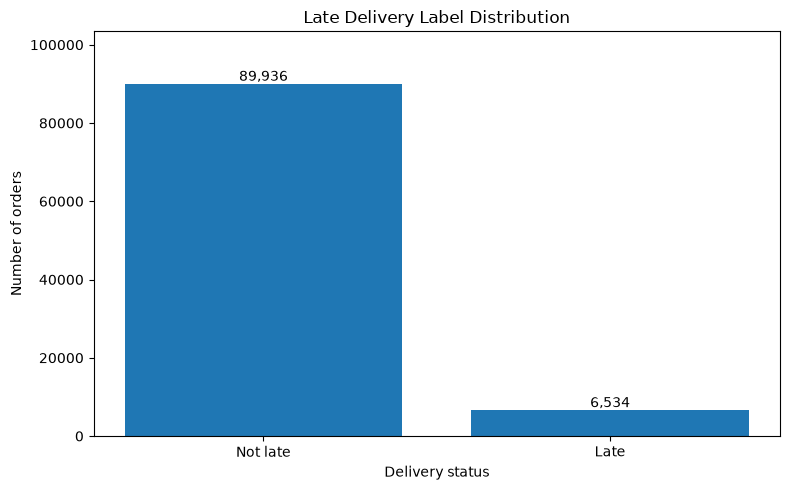

Chart saved successfully!


In [27]:
#14# Thư mục lưu biểu đồ
FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Dữ liệu biểu đồ
labels = ["Not late", "Late"]
counts = [int(not_late_count), int(late_count)]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, counts)

plt.title("Late Delivery Label Distribution")
plt.xlabel("Delivery status")
plt.ylabel("Number of orders")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "late_label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


## 10. Data Export and Documentation

### 10.1. Objective

This stage exports the final research dataset and generates supporting documentation for reproducibility and further statistical analysis.

### 10.2. Research Dataset

The final dataset is exported as `research_data.csv` to the `data/processed/` directory.

The exported file contains:

- 99,441 order-level observations.
- 28 variables.
- One unique record per `order_id`.
- Original order information and derived analytical features.
- Missing values preserved according to the documented rules.

The CSV uses UTF-8 encoding with BOM (`utf-8-sig`) for compatibility with common spreadsheet applications.

### 10.3. Data Dictionary

The `data_dictionary.md` file is generated in the `docs/` directory.

It documents:

- Variable names and descriptions.
- Data types and measurement units.
- Source tables.
- Feature calculation rules.
- Missing-value counts and percentages.
- Data-quality decisions and methodological limitations.

### 10.4. Supporting Outputs

The notebook also generates a visualization of the late-delivery label distribution.

Sample-selection results, missing-value summaries, and data-quality checks are presented within the notebook to support result verification.

### 10.5. Reproducibility

The notebook is designed to execute sequentially from cleaned input data to final output generation.

A complete execution should reproduce the reported dataset dimensions, label distribution, monetary totals, and geographic missing-value counts.

The exported research dataset is intended for use in subsequent descriptive and inferential analyses.


In [28]:
#15# Đường dẫn lưu dữ liệu
output_path = DATA_DIR / "research_data.csv"

# Xuất bảng nghiên cứu
research_data.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("=== EXPORT RESEARCH DATA ===")
print("Saved to:", output_path)

# Đọc lại file để xác minh
research_check = pd.read_csv(
    output_path,
    dtype={"order_id": "string", "customer_id": "string"}
)

print("Rows:", len(research_check))
print("Columns:", len(research_check.columns))
print("Duplicate order_id:",
      research_check["order_id"].duplicated().sum())

assert len(research_check) == 99441
assert research_check["order_id"].is_unique

print("PASS: research_data.csv exported successfully")

=== EXPORT RESEARCH DATA ===
Saved to: C:\Users\Windows\Documents\Group5_STAT3013.R11\data\processed\research_data.csv
Rows: 99441
Columns: 28
Duplicate order_id: 0
PASS: research_data.csv exported successfully


In [29]:
from pathlib import Path
import pandas as pd

# Generate the research data dictionary from the final in-memory dataset.
# Run after the notebook has constructed research_data and geographic features.
DOCS_DIR = ROOT / "docs"
DOCS_DIR.mkdir(parents=True, exist_ok=True)

# Each entry: description, unit/type, source, derivation/rule.
variable_info = {
    "order_id": ("Unique order identifier.", "Identifier", "orders_clean.csv", "Preserved from the orders table; one unique value per order."),
    "customer_id": ("Customer record identifier associated with the order.", "Identifier", "orders_clean.csv", "Preserved from the orders table; links to customers.customer_id."),
    "order_status": ("Recorded operational status of the order.", "Category", "orders_clean.csv", "Preserved from the cleaned orders table."),
    "order_purchase_timestamp": ("Date and time when the order was placed.", "Datetime", "orders_clean.csv", "Parsed as a datetime; unchanged otherwise."),
    "order_approved_at": ("Date and time when the order was approved.", "Datetime", "orders_clean.csv", "Parsed as a datetime; missing values are retained."),
    "order_delivered_carrier_date": ("Date and time when the order was handed to the carrier.", "Datetime", "orders_clean.csv", "Parsed as a datetime; missing values are retained."),
    "order_delivered_customer_date": ("Date and time when the order was delivered to the customer.", "Datetime", "orders_clean.csv", "Parsed as a datetime; used to construct the delivery outcome label."),
    "order_estimated_delivery_date": ("Estimated delivery date recorded for the order.", "Date", "orders_clean.csv", "Parsed as a datetime; compared by calendar date for late-delivery labeling."),
    "flag_approval_before_purchase": ("Quality-control flag indicating approval before purchase.", "Boolean/NA", "orders_clean.csv", "Inherited from the upstream preprocessing pipeline; original flag logic is not recalculated here."),
    "flag_carrier_before_purchase": ("Quality-control flag indicating carrier handoff before purchase.", "Boolean/NA", "orders_clean.csv", "Inherited from the upstream preprocessing pipeline; original flag logic is not recalculated here."),
    "flag_delivery_before_carrier": ("Quality-control flag indicating delivery before carrier handoff.", "Boolean/NA", "orders_clean.csv", "Inherited from the upstream preprocessing pipeline; original flag logic is not recalculated here."),
    "flag_delivery_before_purchase": ("Quality-control flag indicating delivery before purchase.", "Boolean/NA", "orders_clean.csv", "Inherited from the upstream preprocessing pipeline; original flag logic is not recalculated here."),
    "flag_delivered_missing_date": ("Quality-control flag for a delivered order with a missing delivery date.", "Boolean/NA", "orders_clean.csv", "Inherited from the upstream preprocessing pipeline; original flag logic is not recalculated here."),
    "is_late": ("Observed late-delivery outcome for an eligible delivered order.", "0 / 1 / NA", "orders_clean.csv", "1 if actual delivery calendar date is after the estimated date; 0 if on or before it; NA unless status is delivered and required dates exist with delivery not preceding purchase."),
    "purchase_weekday": ("Weekday on which the order was placed.", "Weekday", "orders_clean.csv", "English weekday name extracted from order_purchase_timestamp."),
    "purchase_month": ("Year and month in which the order was placed.", "YYYY-MM", "orders_clean.csv", "Formatted from order_purchase_timestamp."),
    "promised_days": ("Calendar days between approval and estimated delivery.", "Days", "orders_clean.csv", "Estimated delivery date minus approval date after normalization to calendar dates; NA if either date is missing or the result is negative."),
    "customer_state": ("Brazilian state code of the delivery destination.", "State code", "customers_clean.csv", "Joined from customers using customer_id."),
    "items_value": ("Total listed product price for the order, excluding freight.", "BRL", "items_clean.csv", "Sum of price across order items, preserving NA when all prices are missing; NA for orders without items."),
    "freight_value": ("Total freight charge associated with the order items.", "BRL", "items_clean.csv", "Sum of item-level freight_value by order_id, preserving NA when all values are missing; NA for orders without items."),
    "item_count": ("Number of item records associated with the order.", "Count", "items_clean.csv", "Count of item rows grouped by order_id; NA for orders without item records."),
    "seller_count": ("Number of distinct sellers associated with the order.", "Count", "items_clean.csv", "Number of unique seller_id values by order_id; NA for orders without item records."),
    "has_interstate_seller": ("Whether at least one seller is located in a different state from the customer.", "0 / 1 / NA", "customers_clean.csv; sellers_clean.csv; items_clean.csv", "1 if any known seller state differs from the customer state; 0 if all seller states are known and match; NA if indeterminate."),
    "distance_km_mean": ("Mean straight-line distance between the customer and distinct sellers with usable coordinates.", "Kilometers", "geolocation_lookup.csv; customers_clean.csv; sellers_clean.csv; items_clean.csv", "Haversine distance (Earth radius 6,371 km) for each distinct order-seller pair, averaged over valid distances; NA if none is valid. Flagged geographic coordinates are excluded from the mean."),
    "seller_count_with_geo": ("Number of distinct sellers with a usable customer-to-seller distance.", "Count", "geolocation_lookup.csv; items_clean.csv", "Count of nonmissing screened Haversine distances per order; NA for orders without items."),
    "seller_count_total": ("Total distinct sellers in the order-seller geographic aggregation.", "Count", "items_clean.csv", "Distinct seller_id count per order before coordinate screening; NA for orders without items."),
    "has_partial_missing_geo": ("Whether only some distinct sellers lack a usable distance.", "Boolean/NA", "Derived geographic features", "True when 0 < seller_count_with_geo < seller_count_total; False otherwise for orders with items; NA for orders without items."),
    "has_all_missing_geo": ("Whether no distinct seller has a usable distance.", "Boolean/NA", "Derived geographic features", "True when seller_count_with_geo equals zero for orders with items; False otherwise; NA for orders without items."),
}

assert set(variable_info) == set(research_data.columns), (
    "Variable definitions do not match research_data columns: "
    f"missing={set(research_data.columns)-set(variable_info)}, "
    f"extra={set(variable_info)-set(research_data.columns)}"
)
assert research_data["order_id"].notna().all()
assert research_data["order_id"].is_unique

rows = []
for col in research_data.columns:
    description, unit, source, rule = variable_info[col]
    rows.append({
        "Variable": col, "Description": description, "Unit": unit,
        "Source": source, "Calculation": rule,
        "Missing": int(research_data[col].isna().sum()),
        "Missing (%)": round(float(research_data[col].isna().mean() * 100), 2),
    })
dictionary_df = pd.DataFrame(rows)

# Compute quality-control counts from the actual data rather than hardcoding results.
suspicious_zip_count = len(suspicious_zips)
affected_pair_count = int(order_sellers["suspicious_geo_pair"].sum())
affected_order_count = int(order_sellers.loc[order_sellers["suspicious_geo_pair"], "order_id"].nunique())
missing_after = int(research_data["distance_km_mean"].isna().sum())
missing_before = int(len(orders) - order_sellers.groupby("order_id")["distance_km_original"].mean().notna().sum())
orders_without_items = int(research_data["item_count"].isna().sum())
geo_missing = int(geo_agg["distance_km_mean"].isna().sum())
assert geo_missing + orders_without_items == missing_after, "Geographic missingness is inconsistent."

lines = [
    "# Research Data Dictionary", "",
    "## 1. Dataset Overview", "",
    "**Project:** Early Prediction of Late Delivery Risk in Brazilian E-Commerce: A Statistical and Machine Learning Approach", "",
    "**Dataset:** Brazilian E-Commerce Public Dataset by Olist (2016–2018)", "",
    f"**Total orders:** {len(research_data):,}", "",
    f"**Total variables:** {len(dictionary_df)}", "",
    "**Unit of analysis:** One row per unique `order_id`.", "",
    "**Missing-value policy:** Missing information is retained as missing; unknown values are not automatically replaced with zero.", "",
    "---", "",
    "## 2. Data Completeness Summary", "",
    f"- Orders with valid delivery labels: {research_data['is_late'].notna().sum():,}",
    f"- Orders without valid delivery labels: {research_data['is_late'].isna().sum():,}",
    f"- Orders without item records: {orders_without_items:,}",
    f"- Orders missing a usable mean geographic distance: {missing_after:,}", "",
    "---", "",
    "## 3. Variable Definitions", "",
]
for i, row in dictionary_df.iterrows():
    lines.extend([
        f"### 3.{i+1}. `{row['Variable']}`", "",
        f"- **Description:** {row['Description']}",
        f"- **Unit / Type:** {row['Unit']}",
        f"- **Source:** {row['Source']}",
        f"- **Calculation / Rule:** {row['Calculation']}",
        f"- **Missing values:** {row['Missing']:,} ({row['Missing (%)']:.2f}%)", "",
    ])

lines.extend([
    "---", "", "## 4. Data Processing Rules", "",
    "### 4.1. Order-Level Aggregation", "",
    "- Each output record represents one unique order.",
    "- Item-level and order-seller information are aggregated before joining to the orders table.",
    "- Left joins preserve all original orders; orders without items retain missing item-derived features.", "",
    "### 4.2. Late Delivery Labeling", "",
    "- Labels are assigned only to delivered orders with valid purchase, actual delivery, and estimated delivery timestamps, and with actual delivery not preceding purchase.",
    "- Actual and estimated delivery dates are compared by calendar date, not time of day.",
    "- Canceled, undelivered, or otherwise ineligible orders are not coded as on-time deliveries.", "",
    "### 4.3. Multiple Sellers and Missing Coordinates", "",
    "- Each distinct seller is counted once per order when computing mean distance.",
    "- The mean uses available valid distances; partially missing seller coordinates are flagged.",
    "- A missing coordinate never implies zero distance.", "",
    "### 4.4. Temporal Variables", "",
    "- `purchase_weekday` and `purchase_month` are derived from the purchase timestamp.",
    "- `promised_days` counts calendar days from approval to the estimated delivery date.",
    "- Negative or unavailable promised durations remain missing.", "",
    "---", "", "## 5. Geolocation Quality Control", "",
    "- Seller-to-customer distances use the Haversine formula with Earth radius 6,371 km.",
    "- The resulting values are approximate straight-line geographic distances, not transport routes.",
    "- A preliminary screening rule flags coordinates outside latitude [-35, 6] and longitude [-75, -30] degrees.",
    f"- Flagged ZIP prefixes: {suspicious_zip_count:,}.",
    f"- Affected distinct order-seller pairs: {affected_pair_count:,}.",
    f"- Affected distinct orders: {affected_order_count:,}.",
    f"- Orders with missing distance before coordinate screening: {missing_before:,}.",
    f"- Orders with missing distance after coordinate screening: {missing_after:,}.",
    f"- Additional orders with missing distance after screening: {missing_after-missing_before:,}.",
    "- Screened distances are set to missing; no orders or ZIP identifiers are deleted.",
    "- This approximate geographic screen is an additional methodological quality-control decision, not an exact national-boundary test or proof of erroneous coordinates.",
    "- Statistical IQR outliers are not automatically removed.", "",
    "---", "", "## 6. Limitations and Appropriate Use", "",
    "- The dataset describes historical Olist transactions from 2016–2018 and is not a random sample of all Brazilian e-commerce orders.",
    "- ZIP-level coordinates are approximations rather than precise delivery addresses.",
    "- Descriptive statistics and observed associations do not establish causality or predictive performance.",
    "- The complete research dataset contains outcomes and post-confirmation information for historical analysis.",
    "- Before early prediction modeling, input features must be independently restricted to information available at the chosen prediction timestamp to prevent data leakage.", "",
    "---", "", "*Automatically generated by `01_research_data_eda.ipynb`.*", "",
])

dictionary_path = DOCS_DIR / "data_dictionary.md"
dictionary_path.write_text("\n".join(lines), encoding="utf-8")

assert len(dictionary_df) == 28
assert dictionary_path.is_file()
print("=== DATA DICTIONARY ===")
print("Variables:", len(dictionary_df))
print("Saved to:", dictionary_path)
print("Missing distances before screening:", missing_before)
print("Missing distances after screening:", missing_after)
print("Suspicious ZIP prefixes:", suspicious_zip_count)
print("Affected orders:", affected_order_count)
print("PASS: English data dictionary generated successfully")
display(dictionary_df)


=== DATA DICTIONARY ===
Variables: 28
Saved to: C:\Users\Windows\Documents\Group5_STAT3013.R11\docs\data_dictionary.md
Missing distances before screening: 1264
Missing distances after screening: 1269
Suspicious ZIP prefixes: 8
Affected orders: 5
PASS: English data dictionary generated successfully


,Variable,Description,Unit,Source,Calculation,Missing,Missing (%)
0,order_id,Unique order identifier.,Identifier,orders_clean.csv,Preserved from the orders table; one unique va...,0,0.00
1,customer_id,Customer record identifier associated with the...,Identifier,orders_clean.csv,Preserved from the orders table; links to cust...,0,0.00
2,order_status,Recorded operational status of the order.,Category,orders_clean.csv,Preserved from the cleaned orders table.,0,0.00
3,order_purchase_timestamp,Date and time when the order was placed.,Datetime,orders_clean.csv,Parsed as a datetime; unchanged otherwise.,0,0.00
4,order_approved_at,Date and time when the order was approved.,Datetime,orders_clean.csv,Parsed as a datetime; missing values are retai...,160,0.16
5,order_delivered_carrier_date,Date and time when the order was handed to the...,Datetime,orders_clean.csv,Parsed as a datetime; missing values are retai...,1783,1.79
6,order_delivered_customer_date,Date and time when the order was delivered to ...,Datetime,orders_clean.csv,Parsed as a datetime; used to construct the de...,2965,2.98
7,order_estimated_delivery_date,Estimated delivery date recorded for the order.,Date,orders_clean.csv,Parsed as a datetime; compared by calendar dat...,0,0.00
8,flag_approval_before_purchase,Quality-control flag indicating approval befor...,Boolean/NA,orders_clean.csv,Inherited from the upstream preprocessing pipe...,160,0.16
9,flag_carrier_before_purchase,Quality-control flag indicating carrier handof...,Boolean/NA,orders_clean.csv,Inherited from the upstream preprocessing pipe...,1783,1.79


In [30]:
#17# 1. Kiểm tra các đơn có khoảng cách lớn nhất
print("=== TOP 10 LONGEST DISTANCES ===")

display(
    research_data[
        [
            "order_id",
            "customer_state",
            "distance_km_mean",
            "seller_count",
            "is_late"
        ]
    ]
    .sort_values("distance_km_mean", ascending=False)
    .head(10)
)


# 2. Kiểm tra các đơn có thời gian cam kết dài nhất
print("\n=== TOP 10 LONGEST PROMISED DAYS ===")

display(
    research_data[
        [
            "order_id",
            "promised_days",
            "order_purchase_timestamp",
            "order_estimated_delivery_date",
            "is_late"
        ]
    ]
    .sort_values("promised_days", ascending=False)
    .head(10)
)


# 3. Phát hiện ngoại lệ bằng quy tắc IQR
outlier_summary = []

for col in ["distance_km_mean", "promised_days", "items_value", "freight_value"]:

    values = research_data[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = ((values < lower) | (values > upper)).sum()

    outlier_summary.append({
        "variable": col,
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
        "outlier_count": int(outlier_count),
        "outlier_percent": round(outlier_count / len(values) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\n=== OUTLIER SUMMARY (IQR METHOD) ===")
display(outlier_df)

=== TOP 10 LONGEST DISTANCES ===


,order_id,customer_state,distance_km_mean,seller_count,is_late
52068,4f1583d080fe1eec5e509335d79b17c6,ES,3710.420173,1.0,1
57267,e9874f4e48ede77b6b9d785ac3755445,RR,3579.262050,1.0,<NA>
43653,9b790ca446b8e28ce5e4382959f6b7df,RR,3398.548220,1.0,0
38176,2889d7816934298a0f5a4a30ef3ffbc7,RR,3387.259491,1.0,0
29,ecab90c9933c58908d3d6add7c6f5ae3,RR,3380.679978,1.0,0
14760,be5cae366c82f548c9a28b353ab44dd0,RR,3379.275054,1.0,0
60603,714f94b6231908bda17ea75f8f9e7c11,RS,3359.336087,1.0,1
46389,f77eb63e272ad822e11bbf97da9c0edd,RR,3357.892563,1.0,0
40596,cedca39b10d8d496f77547b16e2dbf56,AP,3343.126451,1.0,0
34694,14c9f30dcfd7bff68d5663ce8626cc19,AP,3341.293690,1.0,0



=== TOP 10 LONGEST PROMISED DAYS ===


,order_id,promised_days,order_purchase_timestamp,order_estimated_delivery_date,is_late
57160,eec7f369423b033e549c02f3c5381205,154.0,2018-02-06 20:44:56,2018-07-12,0
40094,0607f0efea4b566f1eb8f7d3c2397320,150.0,2018-03-06 09:47:07,2018-08-03,0
15791,c72727d29cde4cf870d569bf65edabfd,145.0,2017-02-07 18:01:15,2017-07-04,0
36034,13bdf405f961a6deec817d817f5c6624,145.0,2017-03-16 02:30:51,2017-08-08,<NA>
33828,69d126e78947276280838ee9361f5505,145.0,2017-03-30 15:23:23,2017-08-22,<NA>
55368,9c94a4ea2f7876660fa6f1b59b69c8e6,143.0,2017-03-14 19:23:22,2017-08-04,<NA>
86444,c2bb89b5c1dd978d507284be78a04cb2,140.0,2017-05-23 22:28:36,2017-10-11,0
67488,40dc2ba6f322a17626aac6244332828c,117.0,2017-10-05 21:39:05,2018-01-30,0
14578,0d5ce32fbaa548555dac4bee840d7705,110.0,2017-07-01 15:47:06,2017-10-19,0
9345,36f66ebfbd144aa6fb39338bd87b0bf9,106.0,2018-02-26 00:11:02,2018-06-13,<NA>



=== OUTLIER SUMMARY (IQR METHOD) ===


,variable,lower_bound,upper_bound,outlier_count,outlier_percent
0,distance_km_mean,-730.98,1715.50,7664,7.81
1,promised_days,1.50,45.50,1890,1.90
2,items_value,-110.10,305.90,7913,8.02
3,freight_value,-1.44,39.33,9941,10.08



## 11. Research Scope and Data Leakage Considerations

### 11.1. Current Research Scope

The current notebook constructs an analytical dataset for descriptive and inferential statistical analysis.

It contains both observed delivery outcomes and explanatory characteristics.

No predictive model is trained or evaluated in this stage.

### 11.2. Target Variable

The outcome variable `is_late` is determined using actual and estimated delivery dates.

It is retained as the target variable for analyses requiring observed delivery outcomes.

### 11.3. Data Leakage Risk

The research dataset includes information that may only become available after order confirmation, such as:

- `order_status`
- `order_delivered_carrier_date`
- `order_delivered_customer_date`
- Delivery-related data-quality flags
- `is_late`

These variables are useful for historical analysis, outcome construction, and data validation.

However, information unavailable at the intended prediction time must not be used as an input feature for early prediction.

### 11.4. Prediction-Time Feature Availability

Before developing predictive models, each candidate input variable must be checked against the intended prediction timestamp.

Potentially relevant features include:

- Customer location.
- Seller location.
- Order value.
- Freight value.
- Item and seller counts.
- Purchase timing.
- Estimated delivery duration.

These features are not automatically eligible for modeling. Their availability at the chosen prediction time must be verified.

For example, `promised_days` is calculated using `order_approved_at`, so it is appropriate only if this information is available at the intended prediction point.

### 11.5. Methodological Limitation

The prepared dataset is suitable for historical statistical analysis but is not automatically a leakage-free machine learning feature matrix.

A separate feature-selection and temporal-validation procedure will be required before predictive modeling.
